## <font color = #0288d1>图像分类</font>
### 数据准备

### MNIST数据库一共有4个文件需要下载，分别为:
### 1.  train-images-idx3-ubyte.gz：训练集
### 2.  train-labels-idx1-ubyte.gz：训练集图片对应的标签
### 3.  t10k-images-idx3-ubyte .gz：测试集
### 4.  t10k-labels-idx1-ubyte.gz：测试集标签
+ ### 下载后是4个压缩文件。将4个压缩文件解压后存放到一个文件夹中，本文是data文件夹。解压后得到的并不是一系列图片，而是.idx1-ubyte和.idx3-ubyte 格式的文件。这是一种IDX数据格式。

+ ### MNIST图像数据集使用形如<font color="purple">**28*28的数组**</font>来表示每个手写体数字，数组中的每个元素对应一个像素点，即每张图像大小固定为28\*28像素。MNIST数据集中的图像都是256阶灰度图，即灰度值0表示白色（背景），255表示黑色（前景），使用值为[0,255]的uint8数据类型表示图像。
+ ### 训练集共60000张图像而测试集有10000张图像。


>### PyTorch内建了对MNIST的支持，可以直接从pytorch得到该数据库。在下载数据库的同时，需要把数据转换为张量，然后标准化。标准化需要知道图像的均值和方差，这需要对60000张训练集中的所有图像进行处理。在此直接从网上搜索除了该数据库图片的参数，即均值为0.1307，标准差为0.3081。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchmetrics as metrics
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import Compose, Normalize, ToTensor
from train_cuda import train

In [2]:
mean = torch.tensor(0.1307)
std = torch.tensor(0.3081)
compose = Compose([ToTensor(), Normalize(mean, std)])
train_dataset = datasets.MNIST("./Datasets", train=True, transform=compose, download=False)
test_dataset = datasets.MNIST("./Datasets", train=False, transform=compose, download=False)
train_loader = DataLoader(train_dataset, batch_size=10000, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2000)

In [3]:
train_dataset[0][0].shape

torch.Size([1, 28, 28])

In [ ]:
fig, ax = plt.subplots(1, 10)
for i in range(10):
    train_images = train_dataset[i][0][0].numpy()
    ax[i].imshow(train_images, cmap="gray")
    ax[i].axis("off")

In [4]:
class ImageShallowModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, x):
        x = self.flatten(x)
        return self.linear(x)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ImageShallowModel().to(device)
lr = 3e-3
epochs = 50
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
train_loss, val_loss = train(
    model, train_loader, test_loader, loss_fn, optimizer, epochs, device
)


Epoch 1/50 - loss: 1.5931 - val_loss: 0.8322
Epoch 2/50 - loss: 0.7019 - val_loss: 0.5273
Epoch 3/50 - loss: 0.5064 - val_loss: 0.4318
Epoch 4/50 - loss: 0.4336 - val_loss: 0.3885
Epoch 5/50 - loss: 0.3962 - val_loss: 0.3625
Epoch 6/50 - loss: 0.3730 - val_loss: 0.3468
Epoch 7/50 - loss: 0.3565 - val_loss: 0.3332
Epoch 8/50 - loss: 0.3441 - val_loss: 0.3237
Epoch 9/50 - loss: 0.3345 - val_loss: 0.3177
Epoch 10/50 - loss: 0.3266 - val_loss: 0.3098
Epoch 11/50 - loss: 0.3198 - val_loss: 0.3053
Epoch 12/50 - loss: 0.3145 - val_loss: 0.3017
Epoch 13/50 - loss: 0.3096 - val_loss: 0.2976
Epoch 14/50 - loss: 0.3053 - val_loss: 0.2943
Epoch 15/50 - loss: 0.3017 - val_loss: 0.2921
Epoch 16/50 - loss: 0.2983 - val_loss: 0.2894
Epoch 17/50 - loss: 0.2953 - val_loss: 0.2874
Epoch 18/50 - loss: 0.2926 - val_loss: 0.2855
Epoch 19/50 - loss: 0.2901 - val_loss: 0.2838
Epoch 20/50 - loss: 0.2879 - val_loss: 0.2827
Epoch 21/50 - loss: 0.2858 - val_loss: 0.2809
Epoch 22/50 - loss: 0.2835 - val_loss: 0.27

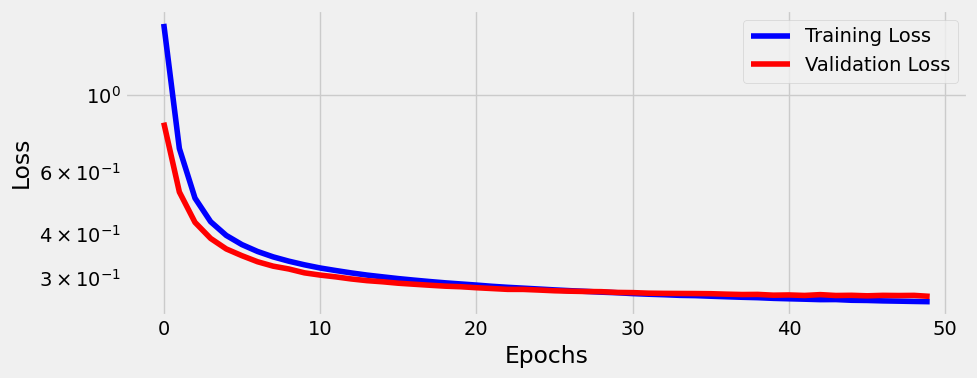

In [6]:
plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_loss, label="Training Loss", c="b")
    plt.plot(val_loss, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [9]:
Accuracy = metrics.Accuracy(task="multiclass", num_classes=10).to(device)
for x, y in test_loader:
    x = x.to(device)
    y = y.to(device)
    yhat = model(x)
    acc = Accuracy(yhat, y)
total_acc = Accuracy.compute()
print(f"Total accuracy: {total_acc:.4f}")

Total accuracy: 0.9251


## 思考题：找出前十个没有识别对的图像

/tmp/ipykernel_4003279/4100894574.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  img = wrong_imgs[i][0] * std.numpy() + mean.numpy()


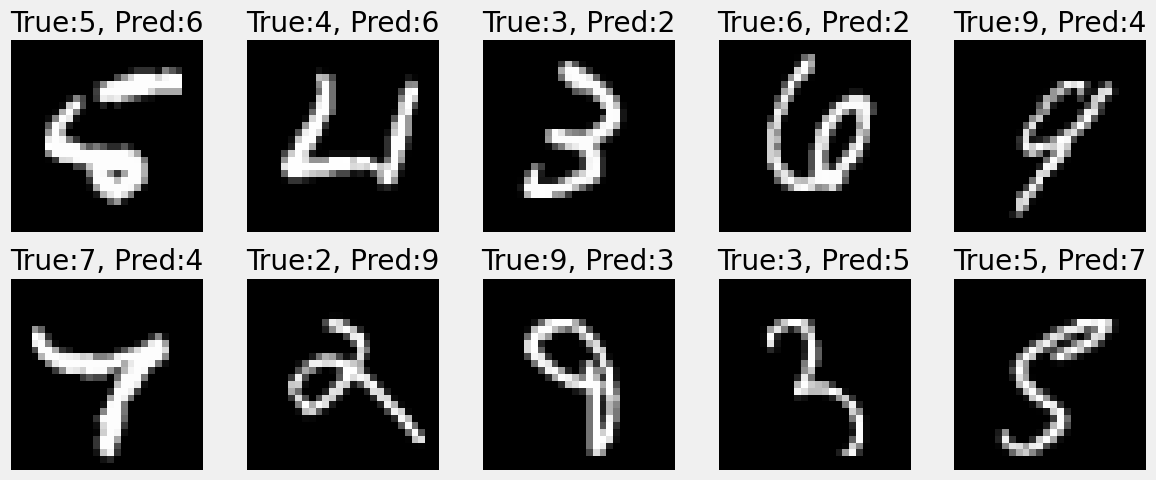

In [10]:
# ========== 追加：找出测试集前10个识别错误的样本并绘图 ==========
model.eval()
wrong_imgs = []
wrong_labels_true = []
wrong_labels_pred = []

with torch.inference_mode():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        pred = torch.argmax(logits, dim=1)

        # 找出本batch里预测不等于真值的索引
        mask = pred != y
        wrong_x_batch = x[mask]
        wrong_y_true_batch = y[mask]
        wrong_y_pred_batch = pred[mask]

        # 逐个加入，凑够10张就停
        for img, yt, yp in zip(wrong_x_batch, wrong_y_true_batch, wrong_y_pred_batch):
            wrong_imgs.append(img.cpu())
            wrong_labels_true.append(yt.item())
            wrong_labels_pred.append(yp.item())
            if len(wrong_imgs) >= 10:
                break
        if len(wrong_imgs) >= 10:
            break

# 绘图
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    # 反归一化：img = img * std + mean
    img = wrong_imgs[i][0] * std.numpy() + mean.numpy()
    plt.imshow(img, cmap="gray")
    plt.title(f"True:{wrong_labels_true[i]}, Pred:{wrong_labels_pred[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
